In [2]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "16"

import numpy as np
import pandas as pd
import scipy as sp
import matplotlib.pyplot as plt
from matplotlib.patches import Arc
import matplotlib.patheffects as pe
import pickle
import seaborn as sns
import sklearn
import torch
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
import statsmodels

import sys
sys.path.append('2D_gastruloids_v5')
import fns_plotting_scripts as fns_plot
import fns_NN
import IIF_analysis as IIF

import importlib
importlib.reload(IIF);
importlib.reload(fns_plot);

import warnings
from sklearn.exceptions import InconsistentVersionWarning
import time
import matplotlib.colors as mcolors

warnings.filterwarnings("ignore", category=InconsistentVersionWarning)

## Data

In [3]:
# LOAD DATA 
file_suffix = '.png'

#data = pd.read_csv(dataDir + '/exp20_data_bgsub_scaled_250716.csv', index_col=0)
dataDir = '250509_Exp20'
data = pd.read_csv(dataDir + '/exp20_data_bgsub_scaled_250509.csv', index_col=0) # '/expZ2_normalized_signals_251024.csv')
data.index.name = None
data.rename(columns={'SOX17_1': 'SOX17'}, inplace=True)
data.rename(columns={'DAPI_1': 'DAPI'}, inplace=True)

# SPECIFY METADATA
tol = {'DAPI':[1,99],'ISL1':[1,99],'TFAP2C':[1,99],'SOX17':[1,99],'TBXT':[1,99],'SOX2':[1,99],'NANOG':[1,99],'TBX6':[1,99],'SMAD23':[1,99]};
conditions = ['B50','B200','B10']

gene_names = ['ISL1', 'GATA3', 'HAND1', 'CDX2', 'TFAP2C', 'SOX17', 'PRDM1', 'SNAI1', 'MIXL1', 'EOMES', 'TBXT', 'TBX6', 'OCT4', 'NANOG','SOX2', 'OTX2']# 'FOXA2',
thresh = {'ISL1': 500, 'GATA3': 700, 'HAND1': 500, 'CDX2': 600, 'TFAP2C': 600, 'SOX17': 500, 'PRDM1': 650, 'NANOG': 1600, 'TBX6': 375, 'TBXT': 285, 'MIXL1': 400, 'EOMES': 200, 'SNAI1': 300, 'OCT4': 500, 'SOX2': 400, 'OTX2': 400}
markers = list(thresh.keys()) # redudnant with gene_names but slightly different order which i'm keeping for consistency with fig2

signal_names = ['pSMAD1','ncYAP','LEF1','BCat','ncSMAD23','ncSMAD2','cytopERK','cytopAKT']
signal_names_simplified = ['pSMAD1','YAP','LEF1','β-cat','SMAD2/3','SMAD2','pERK','pAKT']
clean_signal_names = dict(zip(signal_names,signal_names_simplified))
feature_names = ['nucArea', 'nucVolume','nucMajorAxis', 'nucMinorAxis', 'nucCircularity', 'CircleEdgeDist','RadialDist']


# remove a few rows of bad data, reindex
mask = data[signal_names + gene_names].isna() | (data[signal_names + gene_names] < 0)
mask = mask.any(axis=1)
print(np.sum(mask))
data = data[~mask]
data.index = range(0, len(data))

meta = IIF.Metadata();
meta.xres = 0.325;
meta.yres = 0.325;
meta.channels = signal_names+gene_names;
meta.conditions = conditions;

9


In [4]:
# CONVERT DATA INTO EXPERIMENT AND COLONY OBJECTS
col = dict();
for colID in np.unique(data['Colony']):
    col[colID] = IIF.Colony(data[data['Colony']==colID], colID, meta, features=feature_names, nominalRadius=350);
    col[colID].calcRadialProfiles(cellsPerBin=100, overlap=0, dr=8)
    col[colID].calcPosError(sigma=1)

exp = IIF.MPexperiment(col, meta);
exp.calcRadialProfiles(cellsPerBin=100, overlap=0)

B50, Nbins = 304
B200, Nbins = 288
B10, Nbins = 252


In [29]:
# Load colony images
percentiles = {'pSMAD1': [50, 99.9],
 'YAP': [10, 99.9],
 'BCAT': [1, 99],
 'LEF1': [1, 99],
 'SMAD23': [1, 99],
 'pERK': [5, 99],
 'pAKT': [10, 99],
 'SMAD2': [1, 99],
 'ISL1': [90, 99.6],
 'GATA3': [1, 99],
 'HAND1': [1, 99],
 'CDX2': [1, 99],
 'TFAP2C': [1, 99],
 'SOX17': [1, 99],
 'PRDM1': [90, 99.5],
 'SNAI1': [1, 99],
 'MIXL1': [1, 99],
 'EOMES': [1, 99],
 'TBXT': [1, 99],
 'TBX6': [80, 99],
 'OCT4': [1, 99],
 'NANOG': [40, 99],
 'SOX2': [1, 99],
 'OTX2': [1, 99],
 'DAPI': [1, 99]}

loading 250509_Exp20\230110_6i9rd_exp20_RD1_SMAD23_pAKT_SOX17\MIP\stitched_MIP_p0000_w0003_t0000.jpg
loading 250509_Exp20\230114_6i9rd_exp20_RD5_TFAP2C_NANOG_pERKbad\MIP\stitched_MIP_p0000_w0001_t0000.jpg
loading 250509_Exp20\230116_6i9rd_exp20_RD7_SOX2_PRDM1_SOX17\MIP\stitched_MIP_p0000_w0001_t0000.jpg


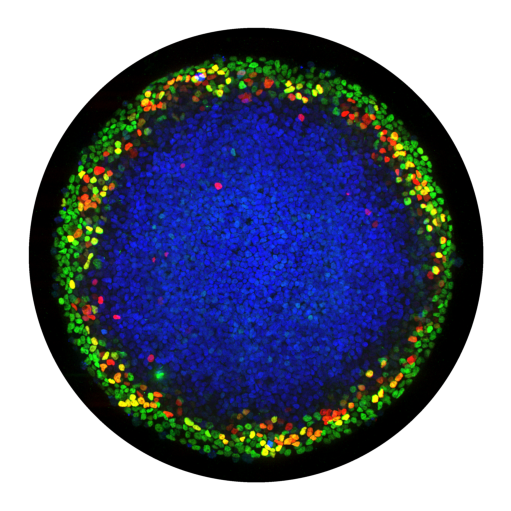

In [36]:
# example channel overlay
colID = 1
#stains = signal_names_simplified 
stains = ['SOX17', 'TFAP2C', 'SOX2']

overlay_markers = [None]
for ov in overlay_markers:
    fig, ax = plt.subplots(1, 1, figsize=(5, 5), constrained_layout=True)
    overlay_marker = ov
    
    RGBbase, image_meta = IIF.makeRGBbase(col, colID, stains, dataDir, outer_margin=100, crop_margin= 140, center_x_margin = 0, center_y_margin = -0, 
                                percentiles = percentiles, rdStr='RD')
    
    ax.imshow(RGBbase);
    ax.axis('off');
    #ax = plt.gca()
    #ax.set_aspect('equal', adjustable='box')
    #plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
    #plt.tight_layout()
    import imageio
    #imageio.imwrite(dataDir + f'/B50M0p5_SOX17_TFAP2C_SOX2.png', RGBoverlay)

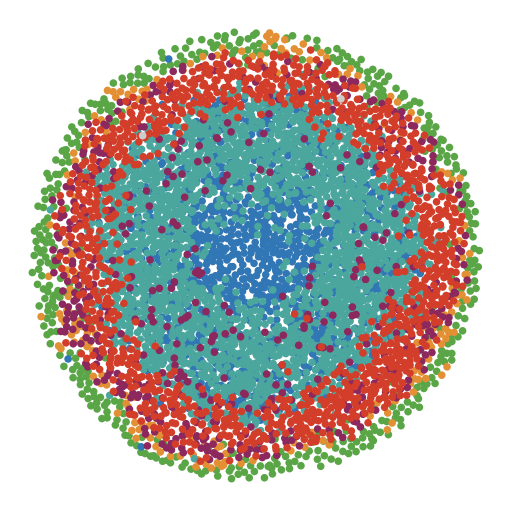

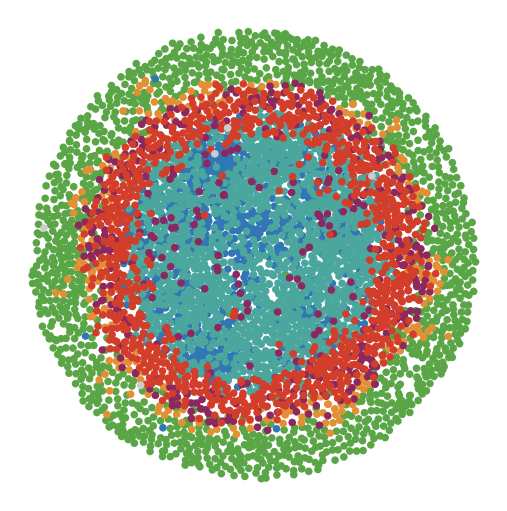

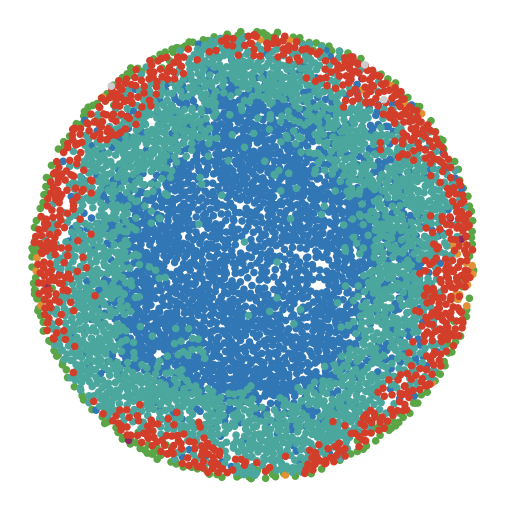

In [5]:
for (cond, colID) in zip(conditions, [1,7,14]):
    fig, ax = plt.subplots(1,1, figsize=(5,5), constrained_layout=True)
    ms = 30
    lim = 350
    col[colID].scatter_fates(ms=ms, thresh=thresh, ax=ax, legend=False)
    #ax.set_xlim([-lim,lim]);
    #ax.set_ylim([lim,-lim]);

    plt.savefig("Fig4/" + 'fates_scatter_' + cond + '_col' + str(colID) + file_suffix)

## Predictions across conditions

In [6]:
importlib.reload(IIF);

# load predictions from Fig.3 
signals = ['pSMAD1', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'cytopERK']
hyperparam = {'HIDDEN_DIM':32, 'N_LAYERS':2, 'LATENT_DIM': 2}

importlib.reload(IIF);
pred_subs = IIF.getPreds2(data, dataDir, [signals], gene_names, hyperparam, save=True)
pred_sub = pred_subs['BCat_LEF1_cytopERK_ncSMAD23_ncYAP_pSMAD1']['avg']

col_pred = dict();
pred = dict()

col_pred = dict()

for colID in np.unique(pred_sub['Colony']):
    col_pred[colID] = IIF.Colony(pred_sub[pred_sub['Colony']==colID], colID, meta, features=feature_names, nominalRadius=350)
    col_pred[colID].calcRadialProfiles(cellsPerBin=100, overlap=0, dr=8)
    col_pred[colID].calcPosError(sigma=1)

pred = IIF.MPexperiment(col_pred, meta)
pred.calcRadialProfiles(cellsPerBin=100, overlap=0)

loading: 250509_Exp20/Fig3_VIB/Fig3_VIB_BCat_LEF1_cytopERK_ncSMAD23_ncYAP_pSMAD1_B50predonly.csv
B50, Nbins = 304
B200, Nbins = 288
B10, Nbins = 252


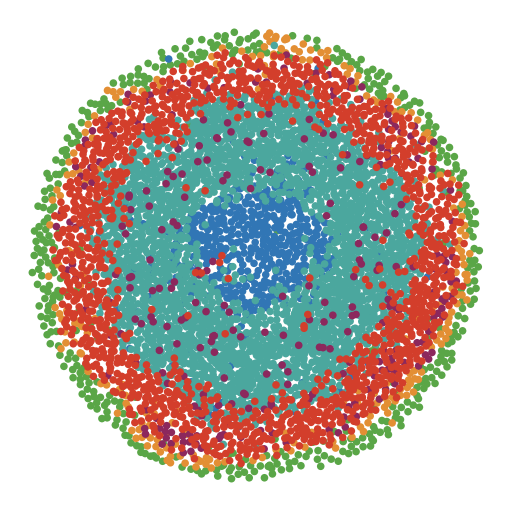

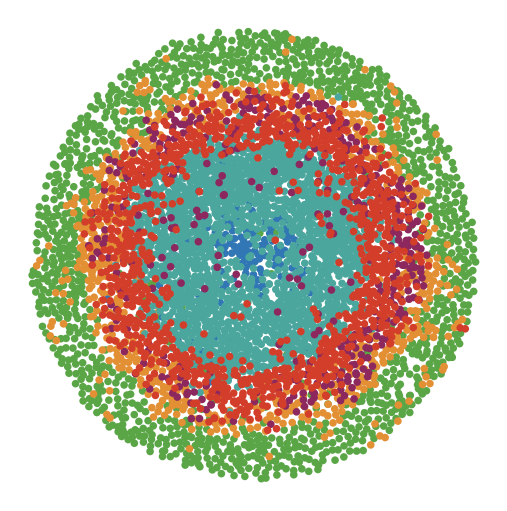

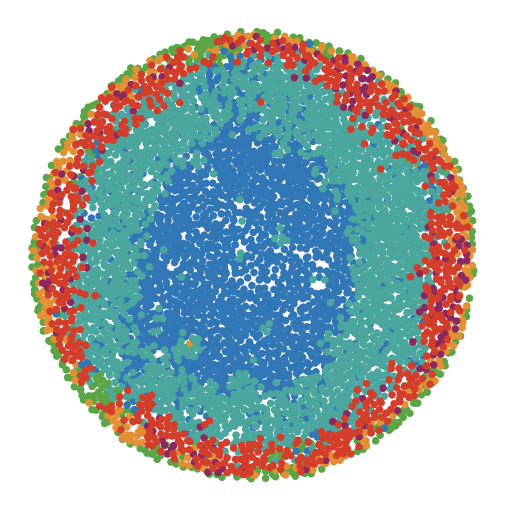

In [7]:
for (cond, colID) in zip(conditions, [1,7,14]):
    fig, ax = plt.subplots(1,1, figsize=(5,5), constrained_layout=True)
    ms = 30
    lim = 350
    col_pred[colID].scatter_fates(ms=ms, thresh=thresh, ax=ax, legend=False)
    #ax.set_xlim([-lim,lim]);
    #ax.set_ylim([lim,-lim]);

    plt.savefig("Fig4/" + 'fates_scatter_' + cond + '_col' + str(colID) + '_pred_'+ str(len(signals)) + 'D' + file_suffix)

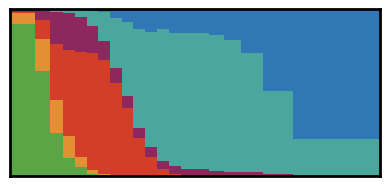

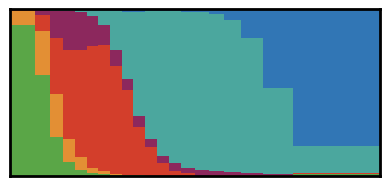

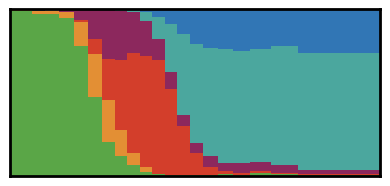

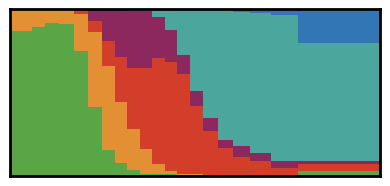

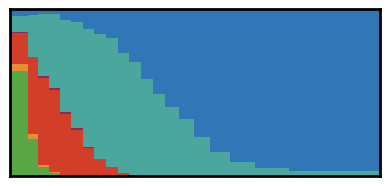

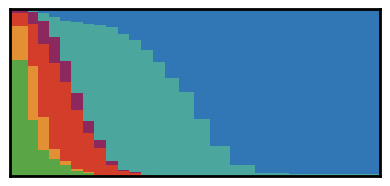

In [9]:
# MAKE HISTOGRAMS OF SPATIAL DISTRIBUTION

n_bins = 20
thresh_boundary = 0.5 # boundaries are half maximum of fate
fate_names_ordered = list(IIF.colmap_fates.keys())
N_fates = len(fate_names_ordered)
colors = list(IIF.colmap_fates.values())

# initialize boundaries array: (n_cond, inner/outer, n_fates, exp/pred)
boundaries_all = np.full((len(conditions), 2, N_fates, 2), np.nan)

for pi, (pred_sub_name, pred_sub) in enumerate(pred_subs.items()):

    pred_sub = pred_sub['avg']
    
    for i, cond in enumerate(conditions):
    
        for mode_sim in [0, 1]:
    
            if mode_sim == 0:
                data_cond = data[data['condition'] == cond]
            elif mode_sim == 1:
                data_cond = pred_sub[pred_sub['condition'] == cond]
            
            fates, fate_names = IIF.return_fates(data_cond, thresh=thresh)
            
            # bin by radial distance
            binning = pd.qcut(data_cond['CircleEdgeDist'], q=n_bins, labels=False, duplicates='drop').to_frame(name='r_bin')
            binning['fate'] = fates

            # get bin centers in microns
            bin_edges = pd.qcut(data_cond['CircleEdgeDist'], q=n_bins, duplicates='drop', retbins=True)[1]
            bin_centers = (bin_edges[1:] + bin_edges[:-1]) / 2

            # fate counts per bin
            fate_counts = binning.groupby(['r_bin', 'fate']).size().unstack(fill_value=0)
            fate_counts = fate_counts.reindex(columns=fate_names_ordered, fill_value=0)

            # normalize per fate (each fate peaks at 1) for boundary detection
            fate_counts_byfate = fate_counts.div(fate_counts.sum(axis=0), axis=1)
            fate_counts_byfate_norm = fate_counts_byfate.div(fate_counts_byfate.max(axis=0).replace(0, 1), axis=1)

            # normalize per bin for bar plot
            fate_counts_norm = fate_counts.div(fate_counts.sum(axis=1), axis=0)

            # fill boundaries array
            for fi, fate in enumerate(fate_names_ordered):

                if fate not in fate_counts_byfate_norm.columns:
                    continue

                profile = fate_counts_byfate_norm[fate].values
                n = len(profile)

                if profile[0] > thresh_boundary:
                    boundaries_all[i, 0, fi, mode_sim] = 0
                if profile[-1] > thresh_boundary:
                    boundaries_all[i, 1, fi, mode_sim] = bin_centers[-1]

                for b in range(1, n - 1):
                    if profile[b-1] < thresh_boundary and profile[b+1] > thresh_boundary:
                        boundaries_all[i, 0, fi, mode_sim] = bin_centers[b]
                    elif profile[b-1] > thresh_boundary and profile[b+1] < thresh_boundary:
                        boundaries_all[i, 1, fi, mode_sim] = bin_centers[b]
            
            # distribution bar plot
            fig, ax = plt.subplots(1, 1, figsize=(4, 3))

            # old version with equal width bin display
            # fate_counts_norm.plot(kind='bar', color=colors, stacked=True, ax=ax, width=1, legend=False)
            # ax.set_xticks([0, n_bins-1], labels=['edge', 'center'], rotation=0)
            # ax.set_xlim(-0.5, n_bins - 0.5)

            bin_widths = bin_edges[1:] - bin_edges[:-1]
            bottom = np.zeros(len(bin_centers))
            for fi, fate in enumerate(fate_names_ordered):
                if fate not in fate_counts_norm.columns:
                    continue
                vals = fate_counts_norm[fate].values
                ax.bar(bin_centers, vals, width=bin_widths, bottom=bottom,
                    color=colors[fi], align='center')
                bottom += vals
            #ax.set_xticks([bin_centers[0], bin_centers[-1]], labels=['edge', 'center'])
            ax.set_xticks([])
            ax.set_xlim(bin_edges[0], bin_edges[-1])
            #ax.set_title(cond)
            ax.set_xlabel(None)
            ax.set_yticks([])
            ax.set_ylim(0, 1)
            
            sw = 2
            ax.set_box_aspect(0.45)
            for spine in ax.spines.values():
                spine.set_linewidth(sw)
            
            mode_str = 'exp' if mode_sim == 0 else 'pred'
            plt.tight_layout()
            plt.savefig("Fig4/" + f'fatedist_{str(pred_sub_name)}_{cond}_{mode_str}_{str(len(signals))}D.png', bbox_inches='tight')
            plt.show()
            plt.close()

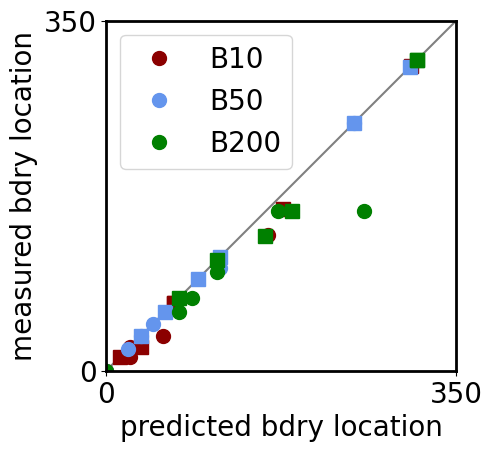

In [10]:
# fate boundaries

fs = 20
sw = 2

fig, ax = plt.subplots(1, 1, figsize=(5, 5))

conditions_ordered = ['B10', 'B50', 'B200']

ax.plot([0, 350], [0, 350], '-', color='grey')

for it_cond, cond in enumerate(conditions_ordered):

    color = fns_plot.return_colmaps('conditions')[conditions.index(cond)]
    boundaries = boundaries_all[conditions.index(cond), :, :, :]

    ax.plot(boundaries[0, :, 1], boundaries[0, :, 0], 'o', color=color, label=cond, markersize=10)
    ax.plot(boundaries[1, :, 1], boundaries[1, :, 0], 's', color=color, markersize=10)

ax.set_xlim([0, 350])
ax.set_ylim([0, 350])
ax.set_xticks([0, 350])
ax.set_yticks([0, 350])
ax.tick_params(labelsize=fs)
ax.set_xlabel('predicted bdry location', fontsize=fs)
ax.set_ylabel('measured bdry location', fontsize=fs)
ax.set_box_aspect(1)
ax.legend(fontsize=fs)

for spine in ax.spines.values():
    spine.set_linewidth(sw)

plt.tight_layout()
plt.savefig("Fig4/" + f'fates_boundaries_allcond_{str(len(signals))}D.png')
plt.show()

### Compare prediction across vs within conditions

In [11]:
importlib.reload(IIF);
N_run = 3
hyperparam = {'HIDDEN_DIM':32, 'N_LAYERS':2, 'LATENT_DIM': 2}

data_B10 = data[data['condition']=='B10']
within_pred_B10, _ = IIF.sig2fate(data_B10, signals, gene_names, N_run, hyperparam)

data_B200 = data[data['condition']=='B200']
within_pred_B200, _ = IIF.sig2fate(data_B200, signals, gene_names, N_run, hyperparam)

  Run 0/3
Elapsed time: 44.79920530319214 seconds
  Run 1/3
Elapsed time: 41.651161670684814 seconds
  Run 2/3
Elapsed time: 39.74769043922424 seconds
  Run 0/3
Elapsed time: 57.95820593833923 seconds
  Run 1/3
Elapsed time: 53.2217960357666 seconds
  Run 2/3
Elapsed time: 56.54445934295654 seconds


In [12]:
within_pred_combined = pred_subs['BCat_LEF1_cytopERK_ncSMAD23_ncYAP_pSMAD1']['avg'].copy()

# overwrite gene predictions for B10 and B200 with within-condition predictions
b10_idx = within_pred_combined['condition'] == 'B10'
b200_idx = within_pred_combined['condition'] == 'B200'

within_pred_combined.loc[b10_idx, gene_names] = within_pred_B10[gene_names].values
within_pred_combined.loc[b200_idx, gene_names] = within_pred_B200[gene_names].values

In [13]:
importlib.reload(IIF);

col_withinpred = dict()

for colID in np.unique(within_pred_combined['Colony']):
    col_withinpred[colID] = IIF.Colony(within_pred_combined[within_pred_combined['Colony']==colID], colID, meta, features=feature_names, nominalRadius=350)
    col_withinpred[colID].calcRadialProfiles(cellsPerBin=100, overlap=0, dr=8)
    col_withinpred[colID].calcPosError(sigma=1)

withinpred = IIF.MPexperiment(col_withinpred, meta)
withinpred.calcRadialProfiles(cellsPerBin=100, overlap=0)

B50, Nbins = 304
B200, Nbins = 288
B10, Nbins = 252


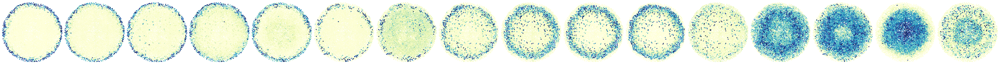

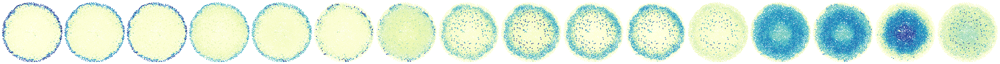

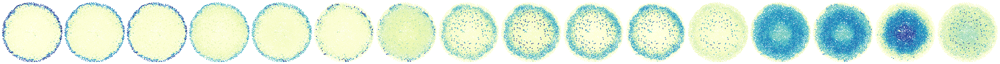

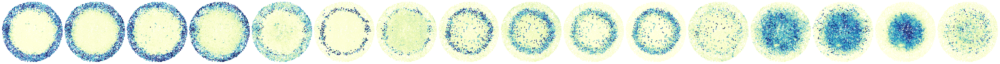

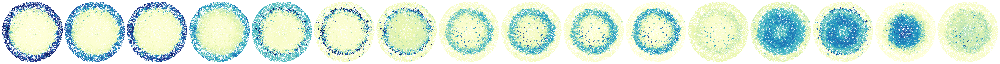

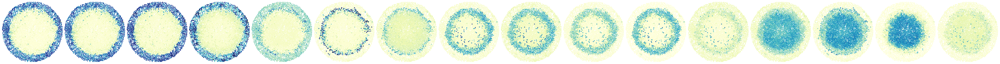

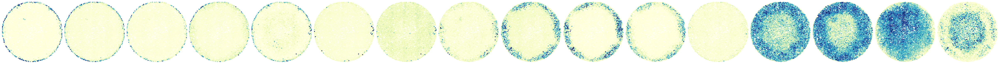

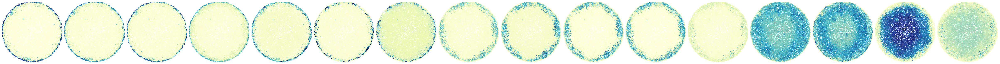

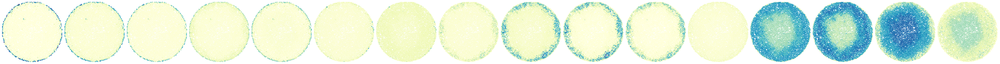

In [15]:
m=1
n = len(gene_names)
vlim = dict()
ms = 10

for (cond, colID) in zip(conditions, [1,7,14]):

    fig, ax = plt.subplots(m,n, figsize=(n*3,m*3), constrained_layout=True)
    
    for i,f in enumerate(gene_names):
    
        if cond=='B50':
            vlim[f] = col[colID].scatter(f, ms=ms, ax=ax[i], tol=(1,99))
        else:
            col[colID].scatter(f, ms=ms, ax=ax[i], vmin=vlim[f][0], vmax=vlim[f][1])
        
        ax[i].set_xlim([-lim,lim])
        ax[i].set_ylim([lim,-lim])
    
    plt.savefig("FigS8/" + 'markers_scatter_' + cond + f'_col{str(colID)}_{str(len(signals))}D.png')
    plt.show()
    plt.close()
    
    fig, ax = plt.subplots(m,n, figsize=(n*3,m*3), constrained_layout=True)
    
    for i,f in enumerate(gene_names):

        col_pred[colID].scatter(f, ms=ms, ax=ax[i], vmin=vlim[f][0], vmax=vlim[f][1])
        
        ax[i].set_xlim([-lim,lim])
        ax[i].set_ylim([lim,-lim])
    
    plt.savefig("FigS8/" + 'markers_scatter_' + cond + f'_col{str(colID)}_pred_across_{str(len(signals))}D.png')
    plt.show()
    plt.close()

    fig, ax = plt.subplots(m,n, figsize=(n*3,m*3), constrained_layout=True)
    
    for i,f in enumerate(gene_names):

        col_withinpred[colID].scatter(f, ms=ms, ax=ax[i], vmin=vlim[f][0], vmax=vlim[f][1])
        
        ax[i].set_xlim([-lim,lim])
        ax[i].set_ylim([lim,-lim])
    
    plt.savefig("FigS8/" + 'markers_scatter_' + cond + f'_col{str(colID)}_pred_within_{str(len(signals))}D.png')
    plt.show()
    plt.close()

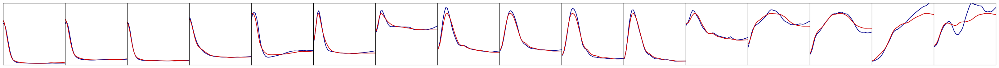

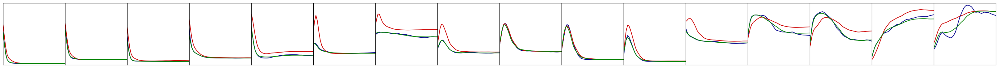

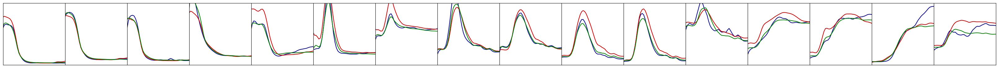

In [16]:
# ---- plot B50 first and save ylims ----
fig, ax = plt.subplots(1, n, figsize=(n*2, 2))
ylims_B50 = {}

for i, f in enumerate(gene_names):
    exp.plotRadialProfiles(f, 'B50', mode='cells', sigma=1, color='darkblue', ax=ax[i], errorbars=False)
    pred.plotRadialProfiles(f, 'B50', mode='cells', sigma=1, color=[0.8, 0, 0], ax=ax[i], errorbars=False)
    ax[i].set_xticks([])
    ax[i].set_yticks([])
    ax[i].set_ylabel(None)
    ax[i].set_xlabel(None)
    ylims_B50[f] = ax[i].get_ylim()  # save ylim for each gene

plt.subplots_adjust(left=0, right=1, top=1, bottom=0, wspace=0, hspace=0)
plt.show()

# ---- plot B10/B200 with same ylims ----
for cond in ['B10','B200']:

    fig, ax = plt.subplots(1, n, figsize=(n*2, 2))

    for i, f in enumerate(gene_names):
        exp.plotRadialProfiles(f, cond, mode='cells', sigma=1, color='darkblue', ax=ax[i], errorbars=False)
        pred.plotRadialProfiles(f, cond, mode='cells', sigma=1, color=[0.8, 0, 0], ax=ax[i], errorbars=False)
        withinpred.plotRadialProfiles(f, cond, mode='cells', sigma=1, color='green', ax=ax[i], errorbars=False)
        ax[i].set_xticks([])
        ax[i].set_yticks([])
        ax[i].set_ylabel(None)
        ax[i].set_xlabel(None)
        ax[i].set_ylim(ylims_B50[f])  # apply B50 ylim

    plt.subplots_adjust(left=0, right=1, top=1, bottom=0, wspace=0, hspace=0)
    plt.savefig("FigS8/" + 'profile_predwithin_v_across' + cond + f'_{str(len(signals))}D.png')
    plt.show()

### Performance

In [19]:
across_pred_combined = pred_subs['BCat_LEF1_cytopERK_ncSMAD23_ncYAP_pSMAD1']['avg'].copy()
pred_subs_2 = {'within': {'avg': within_pred_combined}, 'across': {'avg': across_pred_combined}}

In [20]:
# CALCULATE PERFORMANCE
performances, _ = IIF.calcPerformance(data, pred_subs_2, thresh, gene_names)

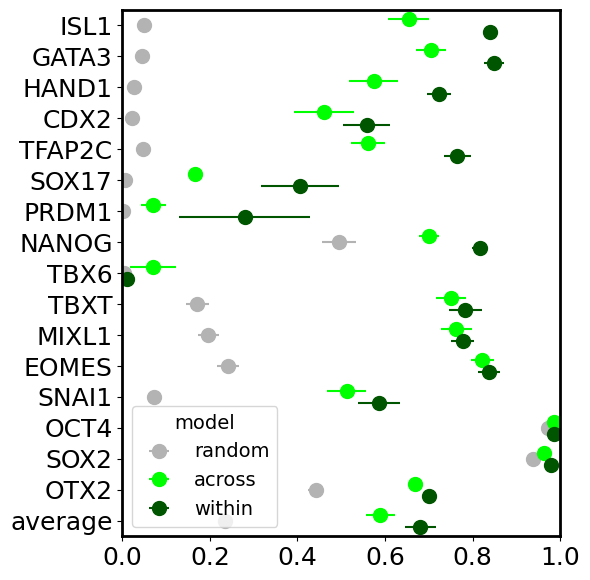

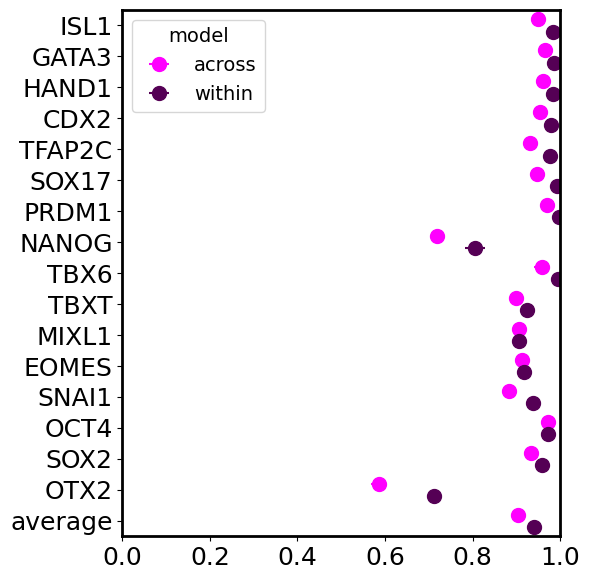

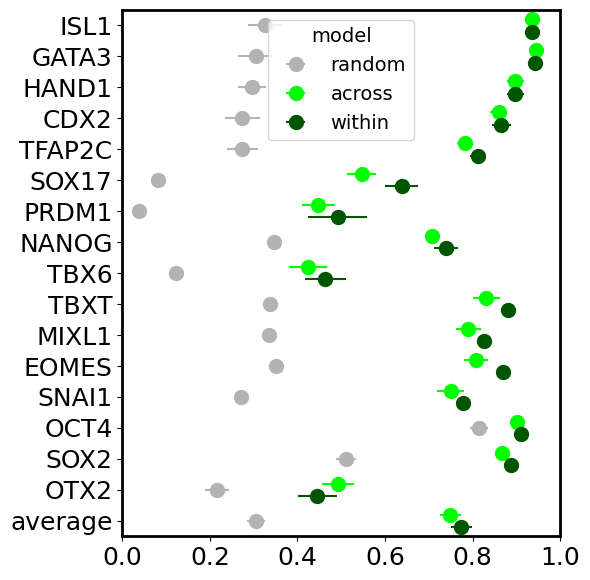

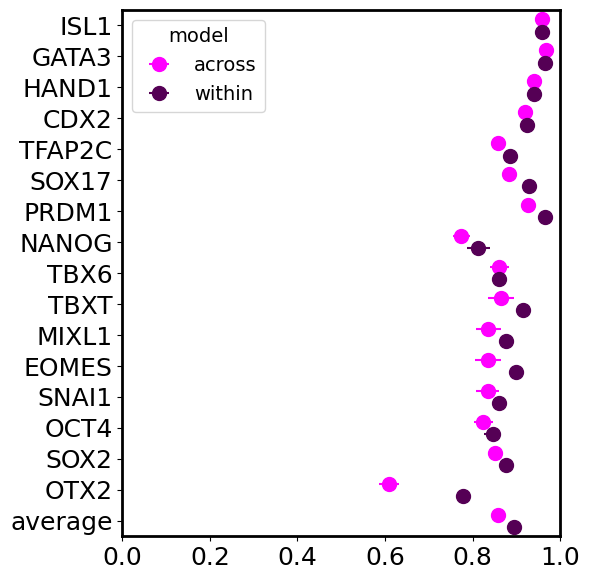

In [21]:
# ============================================================
# PLOT: within vs across vs random - one plot per condition
# ============================================================

performances_compare, _ = IIF.calcPerformance(data, pred_subs_2, thresh, gene_names)

labels = markers + ['marker_avg']
otherlabels = [l for l in performances[cond].index if l not in labels]
otherlabels = otherlabels[1:] + [otherlabels[0]] 

for cond in ['B10','B200']:

    for score in ['f1', 'acc']:

        fig, ax = plt.subplots(figsize=(6, 0.3 * len(labels) + 0.8))
        fs = 18
        ms = 10

        if score == 'f1':
            c_base = np.array([0, 1, 0])
        else:
            c_base = np.array([1, 0, 1])

        # random f1 (only for f1 score)
        if score == 'f1':
            col_rand_avg = 'across-f1_rand-avg'
            col_rand_std = 'across-f1_rand-std'
            available_rand = [l for l in labels
                         if col_rand_avg in performances_compare[cond].columns
                         and not pd.isna(performances_compare[cond].loc[l, col_rand_avg])]
            means_rand = performances_compare[cond].loc[available_rand, col_rand_avg]
            stds_rand  = performances_compare[cond].loc[available_rand, col_rand_std]
            ypos_rand  = [labels.index(l) for l in available_rand]
            ax.errorbar(means_rand, ypos_rand, xerr=stds_rand,
                        fmt='o', color=[0.7, 0.7, 0.7], ms=ms)

        # across and within
        for model_key, divisor, offset in [('across', 1, -0.2), ('within', 3, 0.2)]:

            col_avg = f'{model_key}-{score}-avg'
            col_std = f'{model_key}-{score}-std'

            available = [l for l in labels
                         if col_avg in performances_compare[cond].columns
                         and not pd.isna(performances_compare[cond].loc[l, col_avg])]

            means = performances_compare[cond].loc[available, col_avg]
            stds  = performances_compare[cond].loc[available, col_std]
            ypos  = [labels.index(l) + offset for l in available]

            ax.errorbar(means, ypos, xerr=stds,
                        fmt='o',
                        color=c_base / divisor,
                        ms=ms)

        labels_tick = labels.copy()
        labels_tick[-1] = 'average'

        ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1])
        ax.set_yticks(range(len(labels)), labels_tick)
        ax.tick_params(axis='both', labelsize=fs)
        ax.set_ylim([-0.5, len(labels) - 0.5])
        ax.set_xlim([0, 1])
        #ax.set_title(cond, fontsize=fs)

        sw = 2
        for spine in ax.spines.values():
            spine.set_linewidth(sw)

        plt.gca().invert_yaxis()
        plt.tight_layout()

        if score == 'f1':
            plt.legend(['random', 'across', 'within'], fontsize=fs - 4, title='model', title_fontsize=fs - 4)
        else:
            plt.legend(['across', 'within'], fontsize=fs - 4, title='model', title_fontsize=fs - 4)

        plt.savefig(f'FigS8/marker_{score}_within_vs_across_{cond}_{str(len(signals))}D.png', dpi=150)
        plt.show()

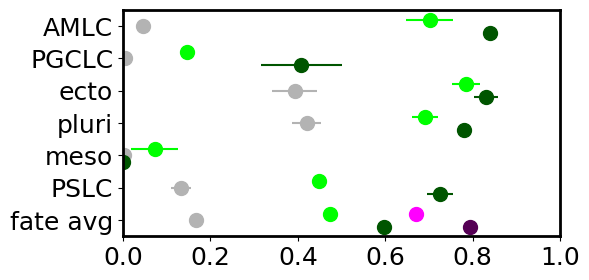

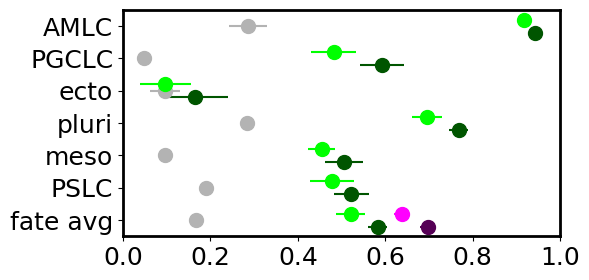

In [22]:
# ============================================================
# PLOT: within vs across vs random - FATE - one plot per condition
# ============================================================

for cond in ['B10', 'B200']:

    labels = otherlabels

    fig, ax = plt.subplots(figsize=(6, 0.3 * len(otherlabels) + 0.8))

    fs = 18
    ms = 10

    for score in ['f1', 'acc']:

        if score == 'f1':
            c_base = np.array([0, 1, 0])
        else:
            c_base = np.array([1, 0, 1])

        # random f1 (only for f1 score)
        if score == 'f1':
            col_rand_avg = 'across-f1_rand-avg'
            col_rand_std = 'across-f1_rand-std'
            available_rand = [l for l in labels
                             if col_rand_avg in performances_compare[cond].columns
                             and not pd.isna(performances_compare[cond].loc[l, col_rand_avg])]
            means_rand = performances_compare[cond].loc[available_rand, col_rand_avg]
            stds_rand  = performances_compare[cond].loc[available_rand, col_rand_std]
            ypos_rand  = [labels.index(l) for l in available_rand]
            ax.errorbar(means_rand, ypos_rand, xerr=stds_rand,
                        fmt='o', color=[0.7, 0.7, 0.7], ms=ms)

        # across and within
        for model_key, divisor, offset in [('across', 1, -0.2), ('within', 3, 0.2)]:

            col_avg = f'{model_key}-{score}-avg'
            col_std = f'{model_key}-{score}-std'

            available = [l for l in labels
                         if col_avg in performances_compare[cond].columns
                         and not pd.isna(performances_compare[cond].loc[l, col_avg])]

            means = performances_compare[cond].loc[available, col_avg]
            stds  = performances_compare[cond].loc[available, col_std]
            ypos  = [labels.index(l) + offset for l in available]

            ax.errorbar(means, ypos, xerr=stds,
                        fmt='o',
                        color=c_base / divisor,
                        ms=ms)

    labels_tick = labels.copy()
    labels_tick[-1] = 'fate avg'

    ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1])
    ax.set_yticks(range(len(labels)), labels_tick)
    ax.tick_params(axis='both', labelsize=fs)
    ax.set_ylim([-0.5, len(labels) - 0.5])
    ax.set_xlim([0, 1])

    #ax.set_title(cond, fontsize=fs)

    sw = 2
    for spine in ax.spines.values():
        spine.set_linewidth(sw)

    plt.gca().invert_yaxis()
    plt.tight_layout()
    #plt.legend(['random', 'across', 'within'], fontsize=fs - 4, title='model', title_fontsize=fs - 4)

    plt.savefig(f'FigS8/fate_f1acc_within_vs_across_{cond}_{str(len(signals))}D.png', dpi=150)
    plt.show()

### Latent space

In [38]:
# Load models from Fig 3
hyperparam = {'HIDDEN_DIM':32, 'N_LAYERS':2, 'LATENT_DIM': 2}
genes = gene_names

cond = 'B50'
data_cond = data[data['condition']==cond]

feat_train = data_cond[signals] 
tar_train = data_cond[gene_names]

run = 12
vib = IIF.VIB(feat_train, tar_train, hyperparam)
vib.model = torch.load(
    os.path.join(dataDir, f'modelws_12_{len(signals)}D.pth'),
    map_location='cpu', weights_only=False
)
model = vib.model

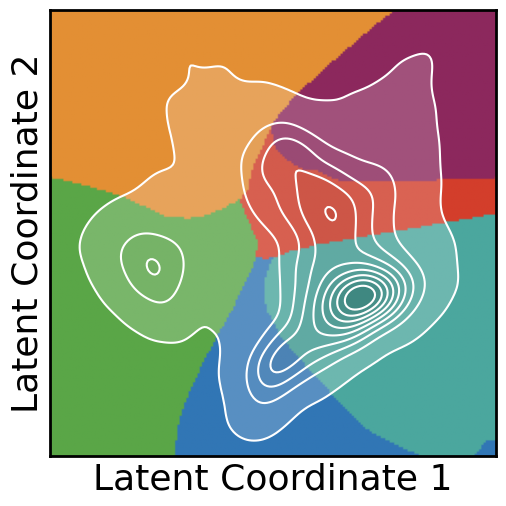

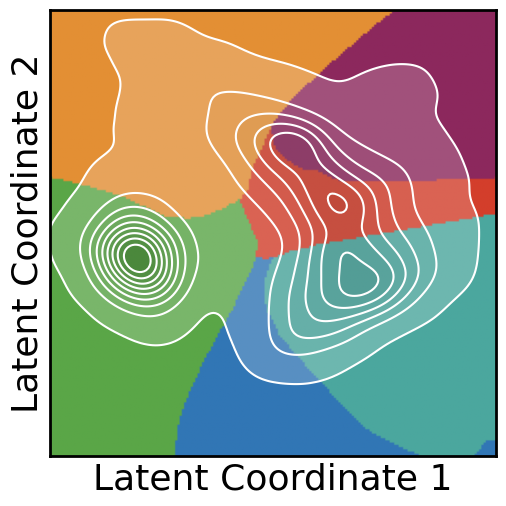

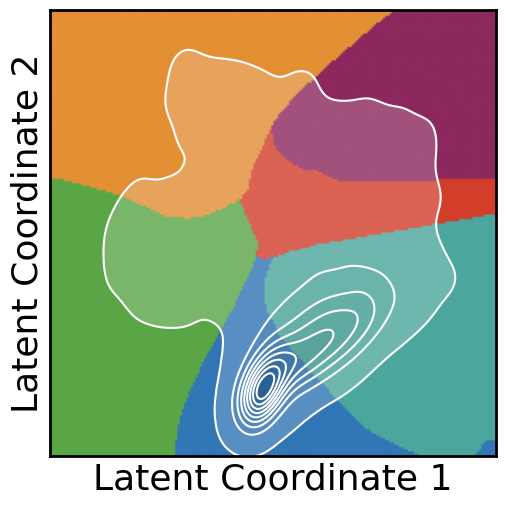

In [42]:
fs = 26
# load fate map
L1grid_scaled = np.load(dataDir + '/fatemap_L1grid_scaled.npy')
L2grid_scaled = np.load(dataDir + '/fatemap_L2grid_scaled.npy')
fates = list(np.load(dataDir + '/fatemap_fates.npy'))
L1smin, L1smax, L2smin, L2smax = np.load(dataDir + '/fatemap_limits.npy')
L1mean, L1std = np.load(dataDir + '/fatemap_L1mean_L1std.npy')
L2mean = np.load(dataDir + '/fatemap_L2mean.npy')

# precompute rgb image once
rgb_image = np.zeros((200, 200, 3))
for i, fate in enumerate(fates):
    color = IIF.colmap_fates[fate]
    rgb_image[i // 200, i % 200] = mcolors.to_rgb(color)

# now loop over conditions
for cond in conditions:

    mask = (data['condition'] == cond)

    # encode with the B50-trained model
    X = vib.scaler_X_run.transform(data.loc[mask, signals])
    X = torch.FloatTensor(X).to(device)

    model.eval()
    with torch.no_grad():
        mu, _ = model.encode(X)

    L1 = mu[:, 0].cpu().numpy()
    L2 = mu[:, 1].cpu().numpy()

    # use same standardization as B50 (same L1mean, L1std)
    L1_scaled = (L1 - L1mean) / L1std
    L2_scaled = (L2 - L2mean) / L1std

    # plot
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    ax.imshow(rgb_image, origin='lower', extent=[L1smin, L1smax, L2smin, L2smax])

    # KDE
    values = np.vstack([L1_scaled, L2_scaled])
    kernel = sp.stats.gaussian_kde(values)
    kde_at_data = kernel(values)
    vmin = np.percentile(kde_at_data, 1)
    kde_grid = kernel(np.vstack([L1grid_scaled.ravel(), L2grid_scaled.ravel()]))
    kde_grid = kde_grid.reshape(L1grid_scaled.shape)
    vmax = kde_grid.max()
    levels = np.linspace(vmin, vmax, 10)

    ax.contourf(L1grid_scaled, L2grid_scaled, kde_grid,
                levels=levels, cmap='Greys', alpha=0.2)
    ax.contour(L1grid_scaled, L2grid_scaled, kde_grid,
               levels=levels, colors='white', linewidths=1.5)

    ax.set_xlim(L1smin, L1smax)
    ax.set_ylim(L2smin, L2smax)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel('Latent Coordinate 1', fontsize=fs)
    ax.set_ylabel('Latent Coordinate 2', fontsize=fs)
    ax.set_aspect('equal', adjustable='box')

    for spine in ax.spines.values():
        spine.set_linewidth(sw)

    plt.tight_layout(pad=0.5)
    plt.savefig('Fig4/LS_fate_' + str(len(signals)) + 'D_run' + str(run) + '_' + cond + '_kde.png', dpi=150, bbox_inches='tight')
    plt.show()